<img src="https://complexsystemsintelligence.github.io/biztonsagkritikus-rendszerek/gyakorlat/assets/logo/pe-cimer-nevjel-fekvo-kek.png" alt="Pannon Egyetem – University of Pannonia" height="56">

[Megnyitás a Google Colabban](https://colab.research.google.com/github/ComplexSystemsIntelligence/biztonsagkritikus-rendszerek/blob/main/gyakorlat/notebookok/10_markov.ipynb) · *Biztonságkritikus rendszerek – gyakorlati útmutató* · © 2026 Abonyi János, Pannon Egyetem · kód: MIT, szöveg: CC BY-NC-SA 4.0

# 10. gyakorlat – Markov-modellek

A notebook a könyv 12. fejezetének modelljeit valósítja meg: javítható elem, javítható 1oo2 rendszer közös okú meghibásodással, hideg tartalék indulási és rejtett hibával, végül a gyorszáró szelepek többfázisú modellje és a nem tökéletes proof teszt.

**Tanulási eredmények:** intenzitásmátrix felírása; tranziens, tartós és elnyelő állapotos megoldás; többfázisú modell periodikus tesztelésre.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats
PE = {"kek": "#285780", "sotet": "#1B3A57", "kiemel": "#E07B39", "zold": "#3E8E63", "piros": "#B83A3A", "lila": "#7A5C99", "szurke": "#6B7280"}
plt.rcParams.update({"figure.figsize": (7.5, 4.2), "axes.grid": True, "grid.color": "#e6e9ee", "axes.spines.top": False,
                     "axes.spines.right": False, "axes.prop_cycle": plt.cycler(color=list(PE.values())), "axes.formatter.use_locale": False})
def hu(x, sig=3):
    """Szám magyar formátumban (tizedesvessző, normálalak)."""
    if x == 0: return "0"
    e = int(np.floor(np.log10(abs(x))))
    if -2 <= e < 5: return f"{x:.{max(0, sig-1-e)}f}".replace(".", ",")
    return f"{x/10**e:.{sig-1}f}".replace(".", ",") + f"·10^{e}"
from scipy.linalg import expm
def tartos(Q):
    n = len(Q); A = np.vstack([Q.T, np.ones(n)]); b = np.zeros(n+1); b[-1] = 1
    return np.linalg.lstsq(A, b, rcond=None)[0]
def mttf(Q, start, elnyelo):
    tr = [i for i in range(len(Q)) if i not in elnyelo]
    N = -np.linalg.inv(Q[np.ix_(tr, tr)]); return N[tr.index(start)].sum()

In [2]:
lam, mu = 1e-4, 1/8
Q = np.array([[-lam, lam], [mu, -mu]])
p = tartos(Q); print("javítható elem: A =", round(p[0], 6), " U =", hu(p[1]), " állásidő:", round(p[1]*8760, 1), "h/év")
for beta in (0.0, 0.05):
    Q = np.array([[-(2*(1-beta)*lam + beta*lam), 2*(1-beta)*lam, beta*lam], [mu, -(mu+lam), lam], [0, mu, -mu]])
    Qa = Q.copy(); Qa[2] = 0
    print(f"1oo2, β = {beta}: U = {hu(tartos(Q)[2])}, MTTF = {hu(mttf(Qa, 0, [2]))} h")

javítható elem: A = 0.999201  U = 7,99·10^-4  állásidő: 7.0 h/év
1oo2, β = 0.0: U = 1,28·10^-6, MTTF = 6,27·10^6 h
1oo2, β = 0.05: U = 4,12·10^-5, MTTF = 1,94·10^5 h


In [3]:
# hideg tartalék: 0 = A üzemel, B tartalék; 1 = A üzemel, B rejtett hiba; 2 = B üzemel; 3 = rendszerhiba
for ps, ld in [(0, 0), (0.02, 0), (0.02, 0.1*lam), (0.05, 0.2*lam)]:
    Q = np.array([[-(lam+ld), ld, lam*(1-ps), lam*ps], [0, -lam, 0, lam], [0, 0, -lam, lam], [0, 0, 0, 0]])
    print(f"p_s = {ps}, λ_d = {ld/lam:.1f}λ: MTTF = {mttf(Q, 0, [3])*lam:.3f}/λ")

p_s = 0, λ_d = 0.0λ: MTTF = 2.000/λ
p_s = 0.02, λ_d = 0.0λ: MTTF = 1.980/λ
p_s = 0.02, λ_d = 0.1λ: MTTF = 1.891/λ
p_s = 0.05, λ_d = 0.2λ: MTTF = 1.792/λ


## Többfázisú modell: gyorszáró szelepek, 1oo2

Állapotok: mindkét szelep jó; egy rejtett hibás; mindkettő hibás. A próbák között nincs javítás; a próba (évente) mindent visszaállít. A PFD(t) fűrészfog alakú.

PFDavg (Markov): 1,220·10^-3  – IEC 61508-6 képlet: 1,227·10^-3


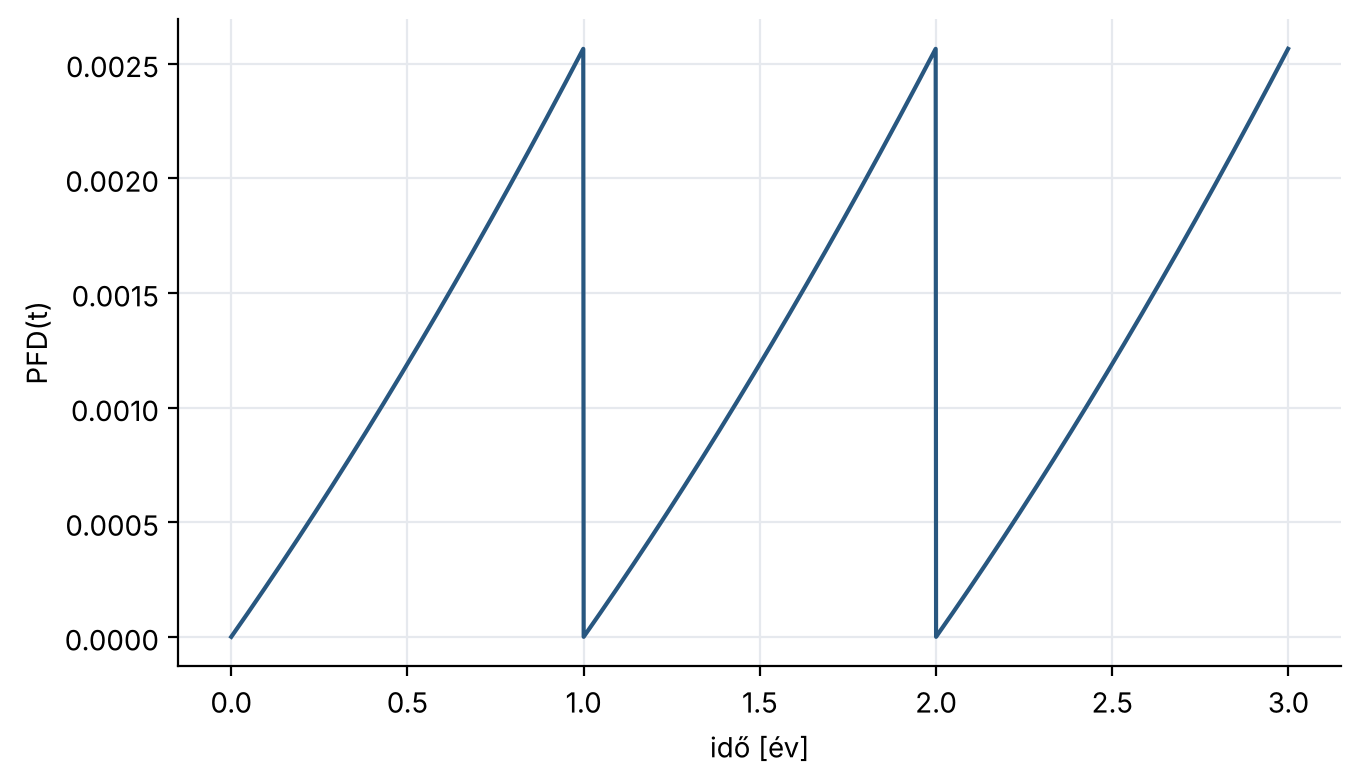

In [4]:
T1, lDU, b = 8760.0, 2.5e-6, 0.10
li, lc = (1-b)*lDU, b*lDU
Q = np.array([[-(2*li+lc), 2*li, lc], [0, -(li+lc), li+lc], [0, 0, 0]])
dt = 10.0; P = expm(Q*dt); x = np.array([1.0, 0, 0]); pfd = []
for k in range(int(3*T1/dt)):
    if k and k % int(T1/dt) == 0: x = np.array([1.0, 0, 0])     # proof teszt
    pfd.append(x[2]); x = x @ P
pfd = np.array(pfd); tt = np.arange(len(pfd))*dt/8760
print("PFDavg (Markov):", hu(pfd.mean(), 4), " – IEC 61508-6 képlet: 1,227·10^-3")
plt.plot(tt, pfd, color=PE["kek"]); plt.xlabel("idő [év]"); plt.ylabel("PFD(t)"); plt.show()

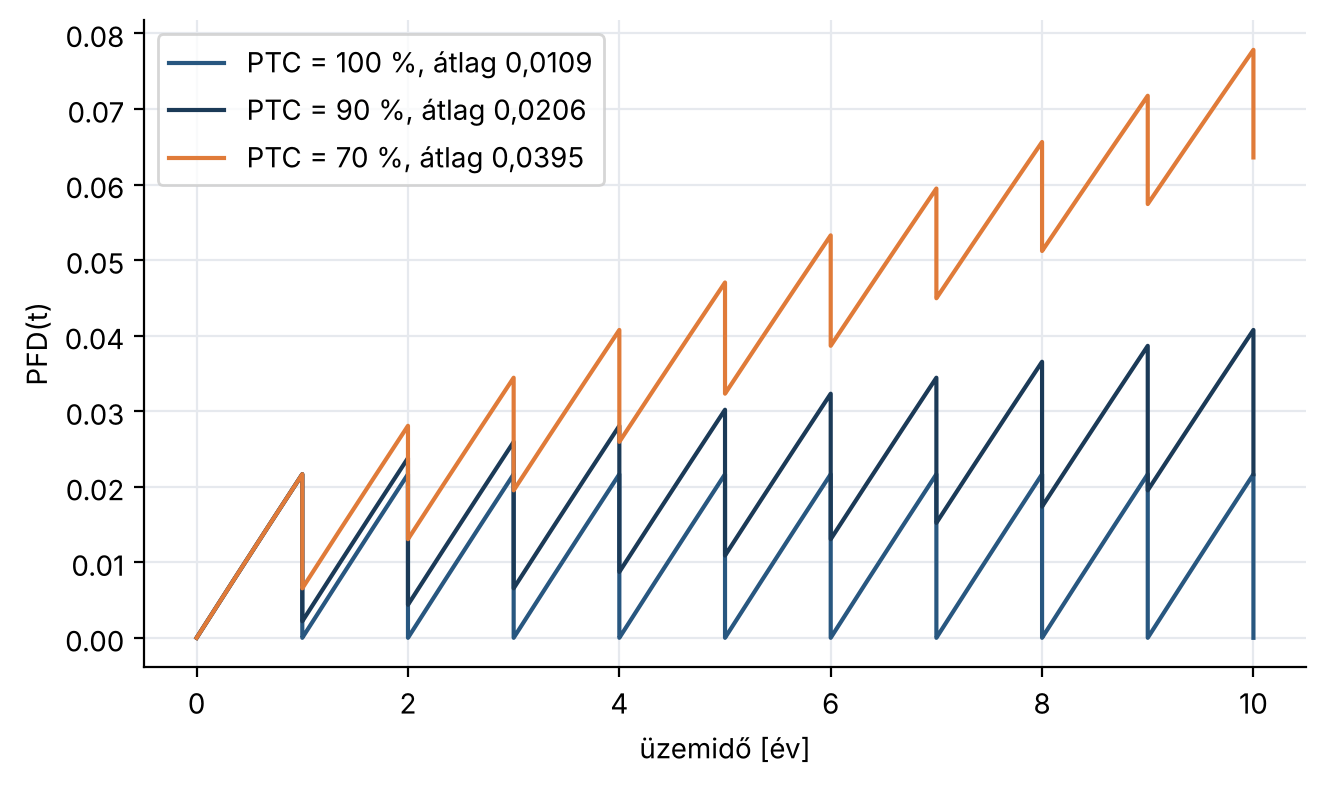

In [5]:
# Nem tökéletes proof teszt: egycsatornás szelep, PTC, nagyjavítás 10 évente
TM = 10*8760; t = np.linspace(0, TM, 200001)
for ptc in (1.0, 0.9, 0.7):
    pf = 1 - np.exp(-ptc*lDU*np.mod(t, T1))*np.exp(-(1-ptc)*lDU*t)
    plt.plot(t/8760, pf, label=f"PTC = {int(ptc*100)} %, átlag {hu(np.trapezoid(pf, t)/TM)}")
plt.xlabel("üzemidő [év]"); plt.ylabel("PFD(t)"); plt.legend(); plt.show()

**1. feladat.** Egészítsd ki a javítható 1oo2 modellt két javítócsapattal (a 2 → 1 átmenet rátája 2μ)! Hogyan változik a tartós rendelkezésre nem állás és az MTTF?

**2. feladat.** Módosítsd a többfázisú modellt úgy, hogy a két szelepet fél év eltolással teszteljék! Csökken-e a PFD<sub>avg</sub>?

## Mintaprompt

*„Írj fel egy Markov-modellt egy 2oo3 szavazású, javítható rendszerre egy javítócsapattal! Add meg az állapotokat és az intenzitásmátrixot, de a megoldást ne számold ki; azt én végzem el Pythonban.”*